# <U>Etapa 1</U>: Importacion de bibliotecas

En esta etapa importamos las bibliotecas que vamos a utilizar para trabajar con el padrón y realizar algunos gráficos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import openpyxl

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


## <U>Etapa 2</U>: Carga del archivo original

El archivo contiene establecimientos educativos de todo el país. Primero vamos a comprobar su ubicación y después lo cargaremos para comenzar a revisarlo.

El Excel original se mantiene sin modificaciones.

In [2]:
BASE = Path.cwd()

if BASE.name.lower() in ["notebooks","notebook"]:
    BASE = BASE.parent

RAW = BASE / "Datos" / "Raw" / "2026.09.07_padron_oficial_establecimientos_educativos_die.xlsx"
PROCESADOS = BASE / "Datos" / "Procesados"
FIGURAS = BASE / "Resultados" / "figuras_padron"

PROCESADOS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

print("Carpeta del proyecto:", BASE)
print("Archivo encontrado:", RAW.exists())
print("Ruta del archivo:", RAW)

Carpeta del proyecto: (raíz del repositorio)
Archivo encontrado: True
Ruta del archivo: Datos/Raw/2026.09.07_padron_oficial_establecimientos_educativos_die.xlsx


### Inspeccion del archivo Excel

Antes de cargar los datos, vamos a comprobar el nombre de la hoja y las primeras filas. Esto es necesario porque el archivo contiene títulos y encabezados antes de los registros.

In [3]:
wb = openpyxl.load_workbook(RAW, read_only=True, data_only=True)

print("Hojas del archivo:", wb.sheetnames)

for hoja in wb.worksheets:
    print(hoja.title, "Filas:", hoja.max_row, "Columnas:", hoja.max_column)

wb.close()

Hojas del archivo: ['padron']
padron Filas: 64508 Columnas: 43


In [4]:
vista = pd.read_excel(RAW, sheet_name="padron", header=None, nrows=14)
vista.iloc[10:14, :13]

,0,1,2,3,4,5,6,7,8,9,10,11,12
10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
11,Establecimiento - Localización,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12,Jurisdicción,Sector,Ámbito,Departamento,Código de departamento,Localidad,Código de localidad,Cueanexo,Nombre,Domicilio,C. P.,Teléfono,Mail
13,Ciudad de Buenos Aires,Privado,Urbano,Comuna 4,02028,CIUDAD DE BUENOS AIRES,02028001,020000100,INSTITUTO PRIVADO ESCUELA EVANGELICA WILLIAM C...,SUÁREZ 684 BOCA,C1162,011 4301-2922/4301-1606,NIVELMEDIOWILLIAMCMORRIS@HOTMAIL.COM / WILLI...


## <U>Etapa 3</U>: Lectura e inspeccion inicial

Los nombres de las columnas se encuentran en la fila 13 y los registros comienzan en la fila 14. Por eso indicamos `skiprows=13` al leer el archivo.

También vamos a asignar nombres claros a las 43 columnas.

In [5]:
columnas = [
    "Jurisdicción", "Sector", "Ámbito", "Departamento", "Código de departamento",
    "Localidad", "Código de localidad", "Cueanexo", "Nombre", "Domicilio",
    "C.P.", "Teléfono", "Mail",
    "Modalidad - Común", "Modalidad - Especial", "Modalidad - Adultos",
    "Común - Nivel inicial - Jardín maternal", "Común - Nivel inicial - Jardín de infantes",
    "Común - Primario", "Común - Secundario", "Común - Secundario - INET",
    "Común - SNU", "Común - SNU - INET", "Común - SNU - Cursos",
    "Especial - Nivel inicial - Educación temprana", "Especial - Nivel inicial - Jardín de infantes",
    "Especial - Primario", "Especial - Secundario",
    "Especial - Integración a modalidad común/adultos",
    "Adultos - Primario", "Adultos - Secundario",
    "Adultos - Formación Profesional", "Adultos - Formación Profesional - INET",
    "Adultos - Alfabetización", "Hospitalaria - Inicial", "Hospitalaria - Primario",
    "Hospitalaria - Secundario", "Talleres - Artística",
    "Servicios complementarios", "Validez_títulos",
    "Total de hogares", "Hogares con población de 3 a 17", "Población de 3 a 17"
]

df = pd.read_excel(RAW, sheet_name="padron", header=None, skiprows=13, dtype=object)
df.columns = columnas

print("Archivo cargado correctamente")
print("Tamaño:", df.shape)

Archivo cargado correctamente
Tamaño: (64495, 43)


In [6]:
print("Primeros 5 registros")
df.head()

Primeros 5 registros


,Jurisdicción,Sector,Ámbito,Departamento,Código de departamento,Localidad,Código de localidad,Cueanexo,Nombre,Domicilio,...,Adultos - Alfabetización,Hospitalaria - Inicial,Hospitalaria - Primario,Hospitalaria - Secundario,Talleres - Artística,Servicios complementarios,Validez_títulos,Total de hogares,Hogares con población de 3 a 17,Población de 3 a 17
0,Ciudad de Buenos Aires,Privado,Urbano,Comuna 4,02028,CIUDAD DE BUENOS AIRES,02028001,020000100,INSTITUTO PRIVADO ESCUELA EVANGELICA WILLIAM C...,SUÁREZ 684 BOCA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.147597,0.137968,0.155235
1,Ciudad de Buenos Aires,Privado,Urbano,Comuna 4,02028,CIUDAD DE BUENOS AIRES,02028001,020000102,INSTITUTO PRIVADO ESCUELA EVANGELICA WILLIAM C...,OLAVARRIA 677 BOCA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.147597,0.137968,0.155235
2,Ciudad de Buenos Aires,Estatal,Urbano,Comuna 4,02028,CIUDAD DE BUENOS AIRES,02028001,020000200,CARLOS R. VIGNALE,WENCESLAO VILLAFAÑE 453 BOCA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.108573,0.090512,0.096383
3,Ciudad de Buenos Aires,Privado,Urbano,Comuna 13,02091,CIUDAD DE BUENOS AIRES,02091001,020000300,INSTITUTO SAN CAYETANO,VIDAL 1743 BELGRANO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.096306,0.052445,0.049545
4,Ciudad de Buenos Aires,Privado,Urbano,Comuna 13,02091,CIUDAD DE BUENOS AIRES,02091001,020000301,INSTITUTO SAN CAYETANO,MOLDES 1764 BELGRANO,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.096306,0.052445,0.049545


In [7]:
print("Informacion del dataset")
df.info()

Informacion del dataset
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 64495 entries, 0 to 64494
Data columns (total 43 columns):
 #   Column                                            Non-Null Count  Dtype 
---  ------                                            --------------  ----- 
 0   Jurisdicción                                      64495 non-null  object
 1   Sector                                            64495 non-null  object
 2   Ámbito                                            64495 non-null  object
 3   Departamento                                      64495 non-null  object
 4   Código de departamento                            64495 non-null  object
 5   Localidad                                         64495 non-null  object
 6   Código de localidad                               64495 non-null  object
 7   Cueanexo                                          64495 non-null  object
 8   Nombre                                            64495 non-null  object
 9   Domi

## <U>Etapa 4</U>: Revision de la calidad de los datos

Vamos a revisar los valores nulos, los registros duplicados y los identificadores. Esto nos permite conocer el estado general del padrón antes de filtrar la provincia.

In [8]:
print("Valores nulos por columna")
df.isnull().sum()

Valores nulos por columna


Jurisdicción                                            0
Sector                                                  0
Ámbito                                                  0
Departamento                                            0
Código de departamento                                  0
Localidad                                               0
Código de localidad                                     0
Cueanexo                                                0
Nombre                                                  0
Domicilio                                               0
C.P.                                                 2419
Teléfono                                                0
Mail                                                11246
Modalidad - Común                                   13668
Modalidad - Especial                                62462
Modalidad - Adultos                                 53778
Común - Nivel inicial - Jardín maternal             59100
Común - Nivel 

In [9]:
print("Registros duplicados exactos:", df.duplicated().sum())
print("Cueanexo duplicados:", df["Cueanexo"].duplicated().sum())
print("Cueanexo diferentes:", df["Cueanexo"].nunique())

Registros duplicados exactos: 0
Cueanexo duplicados: 0
Cueanexo diferentes: 64495


In [10]:
print("Jurisdicciones registradas:", df["Jurisdicción"].nunique())
print("Sectores registrados:", df["Sector"].unique())
print("Ambitos registrados:", df["Ámbito"].unique())

Jurisdicciones registradas: 24
Sectores registrados: ['Privado' 'Estatal' 'Social/cooperativa']
Ambitos registrados: ['Urbano' 'Rural' 'Sin información']


### Revision de las columnas de oferta

Las columnas de modalidad y oferta funcionan como indicadores: el valor `1` señala que el establecimiento cuenta con esa oferta y las celdas vacías indican que no está marcada.

Para poder contarlas, vamos a reemplazar temporalmente los vacíos por `0`. Esta conversión se realiza en el DataFrame de trabajo.

In [11]:
columnas_oferta = columnas[13:40]

for col in columnas_oferta:
    df[col] = pd.to_numeric(df[col], errors="coerce").fillna(0).astype(int)

print("Columnas de oferta revisadas:", len(columnas_oferta))
df[columnas_oferta].head()

Columnas de oferta revisadas: 27


,Modalidad - Común,Modalidad - Especial,Modalidad - Adultos,Común - Nivel inicial - Jardín maternal,Común - Nivel inicial - Jardín de infantes,Común - Primario,Común - Secundario,Común - Secundario - INET,Común - SNU,Común - SNU - INET,...,Adultos - Secundario,Adultos - Formación Profesional,Adultos - Formación Profesional - INET,Adultos - Alfabetización,Hospitalaria - Inicial,Hospitalaria - Primario,Hospitalaria - Secundario,Talleres - Artística,Servicios complementarios,Validez_títulos
0,1,0,0,0,0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,1,0,0,1,1,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,1,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,1,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


### Resumen de las columnas

Vamos a revisar cuántos valores diferentes tiene cada columna y cuántos datos faltantes aparecen. En las banderas de oferta, los ceros indican que la oferta no está marcada.

In [12]:
resumen = pd.DataFrame({
    "valores_diferentes": df.nunique(),
    "valores_nulos": df.isnull().sum(),
    "tipo_dato": df.dtypes.astype(str)
})

resumen

,valores_diferentes,valores_nulos,tipo_dato
Jurisdicción,24,0,object
Sector,3,0,object
Ámbito,3,0,object
Departamento,447,0,object
Código de departamento,528,0,object
Localidad,6954,0,object
Código de localidad,8779,0,object
Cueanexo,64495,0,object
Nombre,54620,0,object
Domicilio,56167,0,object


### Posibles registros repetidos

Además de los duplicados exactos, vamos a revisar coincidencias por jurisdicción, localidad y nombre. Estas coincidencias no se eliminarán automáticamente, porque pueden corresponder a anexos o sedes.

In [13]:
coincidencias = df[df.duplicated(
    subset=["Jurisdicción", "Localidad", "Nombre"],
    keep=False
)].sort_values(["Jurisdicción", "Localidad", "Nombre"])

print("Registros que coinciden en esos campos:", len(coincidencias))
coincidencias.head(10)

Registros que coinciden en esos campos: 4602


,Jurisdicción,Sector,Ámbito,Departamento,Código de departamento,Localidad,Código de localidad,Cueanexo,Nombre,Domicilio,...,Adultos - Alfabetización,Hospitalaria - Inicial,Hospitalaria - Primario,Hospitalaria - Secundario,Talleres - Artística,Servicios complementarios,Validez_títulos,Total de hogares,Hogares con población de 3 a 17,Población de 3 a 17
4845,Buenos Aires,Privado,Urbano,ESTEBAN ECHEVERRIA,06260,9 DE ABRIL,06260001,060254900,INSTITUTO ALMAFUERTE,RESTELLI 1555,...,0,0,0,0,0,0,0,0.321406,0.326729,0.350955
6874,Buenos Aires,Privado,Urbano,ESTEBAN ECHEVERRIA,06260,9 DE ABRIL,06260001,060493100,INSTITUTO ALMAFUERTE,RESTELLI Y SANTAMARÍA 1555,...,0,0,0,0,0,0,0,0.321406,0.326729,0.350955
15770,Buenos Aires,Privado,Urbano,SAN ISIDRO,06756,ACASSUSO,06756001,061607900,COLEGIO DE LA RIBERA,EDUARDO COSTA 1114,...,0,0,0,0,0,0,0,0.074542,0.036494,0.036884
15791,Buenos Aires,Privado,Urbano,SAN ISIDRO,06756,ACASSUSO,06756001,061611500,COLEGIO DE LA RIBERA,EDUARDO ACOSTA 1172,...,0,0,0,0,0,0,0,0.076199,0.044065,0.041414
19242,Buenos Aires,Privado,Urbano,SAN ISIDRO,06756,ACASSUSO,06756001,062120400,COLEGIO DE LA RIBERA,GRAL. GÜEMES 318,...,0,0,0,0,0,0,0,0.076199,0.044065,0.041414
13493,Buenos Aires,Privado,Urbano,SAN ISIDRO,06756,ACASSUSO,06756001,061213500,COLEGIO FLORENCIA NIGHTINGALE,VUELTA DE OBLIGADO 514,...,0,0,0,0,0,0,0,0.076199,0.044065,0.041414
14055,Buenos Aires,Privado,Urbano,SAN ISIDRO,06756,ACASSUSO,06756001,061302900,COLEGIO FLORENCIA NIGHTINGALE,CAMINO DE LA RIBERA SOR CAMINO ROLON 535,...,0,0,0,0,0,0,0,0.076199,0.044065,0.041414
13547,Buenos Aires,Privado,Urbano,SAN ISIDRO,06756,ACASSUSO,06756001,061221100,COLEGIO FRANCO ARGENTINO,LAVALLE E/ URQUIZA Y GÜEMES 1067,...,0,0,0,0,0,0,0,0.076199,0.044065,0.041414
13549,Buenos Aires,Privado,Urbano,SAN ISIDRO,06756,ACASSUSO,06756001,061221300,COLEGIO FRANCO ARGENTINO,LAVALLE 1067,...,0,0,0,0,0,0,0,0.076199,0.044065,0.041414
13494,Buenos Aires,Privado,Urbano,SAN ISIDRO,06756,ACASSUSO,06756001,061213700,INSTITUTO DARDO ROCHA,CATAMARCA E/ MONTEAGUDO Y BERUTTI 875,...,0,0,0,0,0,0,0,0.092808,0.043663,0.04103


## <U>Etapa 5</U>: Analisis general del padron

Antes de trabajar solamente con Jujuy, vamos a observar cómo se distribuyen los establecimientos entre las jurisdicciones.

In [14]:
jurisdicciones = df["Jurisdicción"].value_counts()

print("Cantidad de jurisdicciones:", len(jurisdicciones))
jurisdicciones.head(10)

Cantidad de jurisdicciones: 24


Jurisdicción
Buenos Aires              19988
Córdoba                    5483
Santa Fe                   5044
Chaco                      3088
Misiones                   2996
Entre Ríos                 2959
Mendoza                    2883
Ciudad de Buenos Aires     2749
Santiago del Estero        2262
Tucumán                    2051
Name: count, dtype: int64

In [15]:
tabla_jurisdicciones = jurisdicciones.rename_axis("Jurisdicción").reset_index(name="establecimientos")
tabla_jurisdicciones["porcentaje"] = (
    tabla_jurisdicciones["establecimientos"] / len(df) * 100
).round(2)

tabla_jurisdicciones.head(24)

,Jurisdicción,establecimientos,porcentaje
0,Buenos Aires,19988,30.99
1,Córdoba,5483,8.50
2,Santa Fe,5044,7.82
3,Chaco,3088,4.79
4,Misiones,2996,4.65
5,Entre Ríos,2959,4.59
6,Mendoza,2883,4.47
7,Ciudad de Buenos Aires,2749,4.26
8,Santiago del Estero,2262,3.51
9,Tucumán,2051,3.18


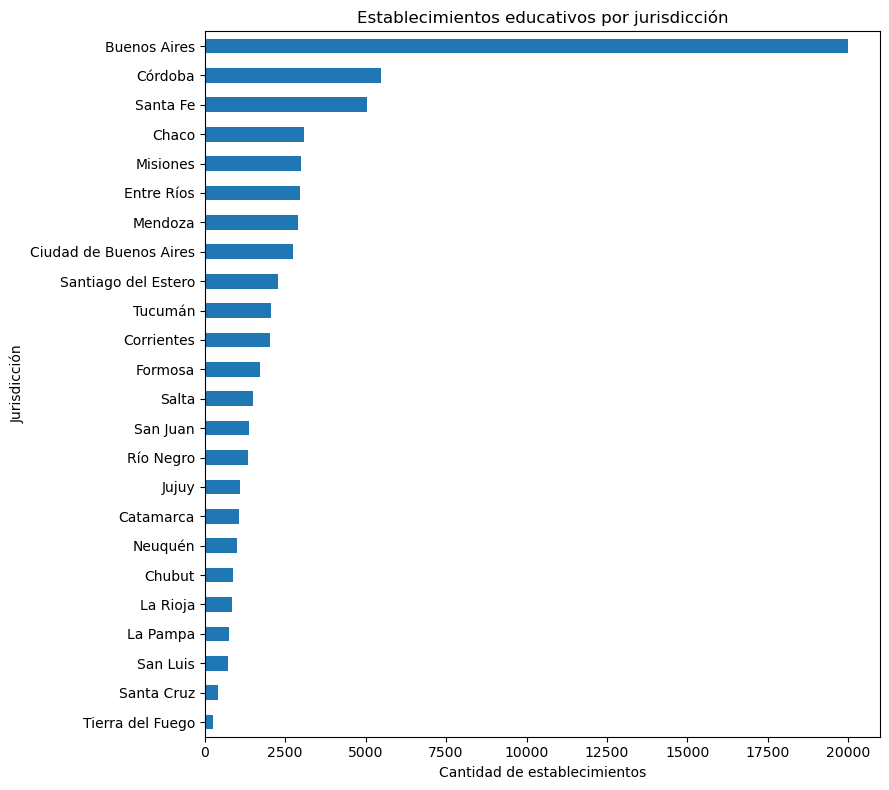

In [16]:
jurisdicciones.sort_values().plot(
    kind="barh",
    figsize=(9, 8)
)

plt.title("Establecimientos educativos por jurisdicción")
plt.xlabel("Cantidad de establecimientos")
plt.ylabel("Jurisdicción")
plt.tight_layout()
plt.show()

## <U>Etapa 6</U>: Filtrado de la provincia de Jujuy

Para nuestro proyecto necesitamos analizar los establecimientos de Jujuy. Vamos a crear un nuevo DataFrame sin modificar el original.

In [17]:
jj = df[df["Jurisdicción"].astype(str).str.strip().str.lower() == "jujuy"].copy()

print("Registros de Jujuy:", len(jj))
print("Departamentos:", jj["Departamento"].nunique())
print("Localidades por nombre:", jj["Localidad"].nunique())
print("Codigos de localidad:", jj["Código de localidad"].nunique())
jj.head()

Registros de Jujuy: 1087
Departamentos: 16
Localidades por nombre: 249
Codigos de localidad: 257


,Jurisdicción,Sector,Ámbito,Departamento,Código de departamento,Localidad,Código de localidad,Cueanexo,Nombre,Domicilio,...,Adultos - Alfabetización,Hospitalaria - Inicial,Hospitalaria - Primario,Hospitalaria - Secundario,Talleres - Artística,Servicios complementarios,Validez_títulos,Total de hogares,Hogares con población de 3 a 17,Población de 3 a 17
39974,Jujuy,Estatal,Urbano,DOCTOR MANUEL BELGRANO,38021,SAN SALVADOR DE JUJUY,38021080,380000100,ESCUELA N 157 DR RICARDO ROJAS,CONSTITUCION 391 CUYAYA INTITUCION EDUCATIVA,...,0,0,0,0,0,0,0,0.140232,0.13522,0.146518
39975,Jujuy,Estatal,Urbano,DOCTOR MANUEL BELGRANO,38021,SAN SALVADOR DE JUJUY,38021080,380000200,ESCUELA N 396 DR ANTONIO ROCHA SOLÓRZANO,OLAVARRIA 501 CUYAYA,...,0,0,0,0,0,0,0,0.140232,0.13522,0.146518
39976,Jujuy,Estatal,Urbano,DOCTOR MANUEL BELGRANO,38021,SAN SALVADOR DE JUJUY,38021080,380000300,ESCUELA N 136 GRAL LAMADRID,ESCOLASTICO ZEGADA 1316 CUYAYA,...,0,0,0,0,0,0,0,0.140232,0.13522,0.146518
39977,Jujuy,Estatal,Urbano,DOCTOR MANUEL BELGRANO,38021,SAN SALVADOR DE JUJUY,38021080,380000400,ESCUELA N 85 23 DE AGOSTO,CONSTITUCION 391 CUYAYA al lado de la salita C...,...,0,0,0,0,0,0,0,0.140232,0.13522,0.146518
39978,Jujuy,Privado,Urbano,DOCTOR MANUEL BELGRANO,38021,SAN SALVADOR DE JUJUY,38021080,380000600,COLEGIO PRIVADO PABLO PIZZURNO - NIVEL SECUNDARIO,LA RIOJA 1970 CUYAYA,...,0,0,0,0,0,0,0,0.140232,0.13522,0.146518


## <U>Etapa 7</U>: Analisis por departamento y localidad

Primero vamos a contar cuántos establecimientos hay en cada departamento. También incluiremos la cantidad de localidades registradas.

In [18]:
departamentos = jj.groupby("Departamento").agg(
    establecimientos=("Cueanexo", "count"),
    localidades=("Código de localidad", "nunique")
).sort_values("establecimientos", ascending=False)

departamentos

,establecimientos,localidades
Departamento,,
DOCTOR MANUEL BELGRANO,341,10
SAN PEDRO,116,20
EL CARMEN,112,22
LEDESMA,97,9
HUMAHUACA,66,31
YAVI,61,31
PALPALA,56,10
COCHINOCA,55,29
SANTA BARBARA,35,12


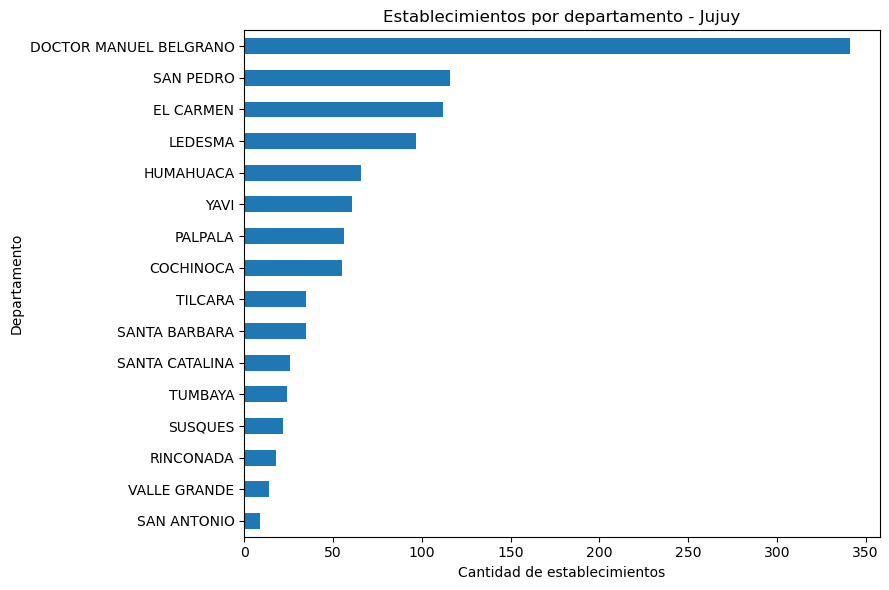

In [19]:
departamentos["establecimientos"].sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Establecimientos por departamento - Jujuy")
plt.xlabel("Cantidad de establecimientos")
plt.ylabel("Departamento")
plt.tight_layout()
plt.show()

### Localidades con mayor cantidad de establecimientos

En el padrón hay nombres de localidades que se repiten en distintos departamentos. Por eso, para contar ubicaciones vamos a utilizar el código de localidad junto con el departamento.

In [20]:
localidades = (
    jj.groupby(["Código de localidad", "Departamento", "Localidad"])
      .size()
      .reset_index(name="establecimientos")
      .sort_values("establecimientos", ascending=False)
)

print("Ubicaciones territoriales:", len(localidades))
localidades.head(15)

Ubicaciones territoriales: 257


,Código de localidad,Departamento,Localidad,establecimientos
56,38021080,DOCTOR MANUEL BELGRANO,SAN SALVADOR DE JUJUY,324
143,38063050,SAN PEDRO,SAN PEDRO,74
98,38035064,LEDESMA,LIBERTADOR GENERAL SAN MARTIN,50
109,38042025,PALPALA,PALPALA,43
45,38014035,EL CARMEN,PERICO,41
240,38112048,YAVI,LA QUIACA,25
42,38014031,EL CARMEN,MONTERRICO,20
1,38007002,COCHINOCA,ABRA PAMPA,18
77,38028042,HUMAHUACA,HUMAHUACA,17
33,38014017,EL CARMEN,EL CARMEN,15


### Nombres de localidades repetidos

Un mismo nombre puede aparecer en más de un departamento. Por eso no debemos utilizar solamente el texto de la localidad para calcular la cobertura.

In [21]:
repetidas = (
    jj.groupby("Localidad")["Departamento"]
      .nunique()
      .loc[lambda x: x > 1]
      .sort_values(ascending=False)
)

print("Nombres que aparecen en más de un departamento:", len(repetidas))
repetidas

Nombres que aparecen en más de un departamento: 8


Localidad
LA CIENAGA       2
PUEBLO VIEJO     2
RIO BLANCO       2
SAN ANTONIO      2
SAN FRANCISCO    2
SAN LUCAS        2
SANTO DOMINGO    2
TUNALITO         2
Name: Departamento, dtype: int64

## <U>Etapa 8</U>: Analisis de sector y ambito

En esta etapa vamos a observar cómo se distribuyen los establecimientos según el tipo de gestión y el ámbito donde se encuentran.

Establecimientos por sector


Sector
Estatal               947
Privado               123
Social/cooperativa     17
Name: count, dtype: int64

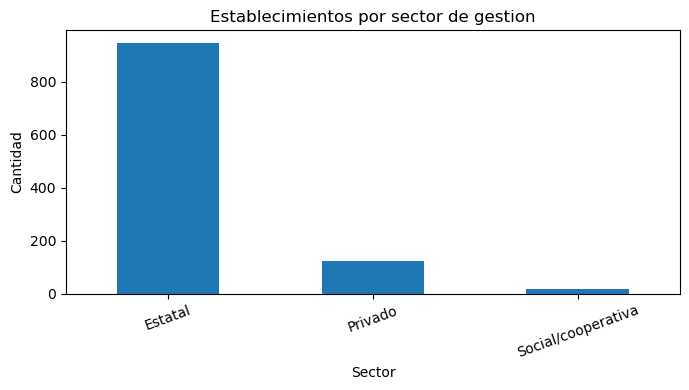

In [22]:
print("Establecimientos por sector")
sector = jj["Sector"].value_counts()
display(sector)

sector.plot(kind="bar", figsize=(7, 4))
plt.title("Establecimientos por sector de gestion")
plt.xlabel("Sector")
plt.ylabel("Cantidad")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

Establecimientos por ambito


Ámbito
Urbano    730
Rural     357
Name: count, dtype: int64

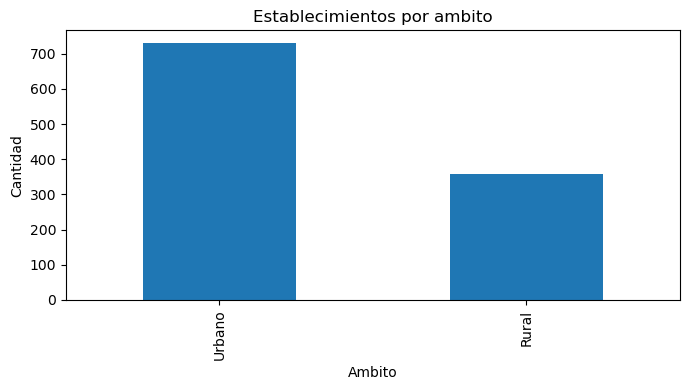

In [23]:
print("Establecimientos por ambito")
ambito = jj["Ámbito"].value_counts()
display(ambito)

ambito.plot(kind="bar", figsize=(7, 4))
plt.title("Establecimientos por ambito")
plt.xlabel("Ambito")
plt.ylabel("Cantidad")
plt.tight_layout()
plt.show()

In [24]:
tabla_sector_ambito = pd.crosstab(jj["Departamento"], [jj["Sector"], jj["Ámbito"]])
tabla_sector_ambito

Sector                 Estatal        Privado        Social/cooperativa       
Ámbito                   Rural Urbano   Rural Urbano              Rural Urbano
Departamento                                                                  
COCHINOCA                   38     17       0      0                  0      0
DOCTOR MANUEL BELGRANO      22    229       1     79                  0     10
EL CARMEN                   28     72       1      6                  2      3
HUMAHUACA                   44     22       0      0                  0      0
LEDESMA                      6     83       0      8                  0      0
PALPALA                     10     39       0      7                  0      0
RINCONADA                   18      0       0      0                  0      0
SAN ANTONIO                  8      0       1      0                  0      0
SAN PEDRO                   28     70       0     17                  0      1
SANTA BARBARA               11     23       0      1                  0      0
SANTA CATALINA              26      0       0      0                  0      0
SUSQUES                     22      0       0      0                  0      0
TILCARA                     19     15       0      0                  0      1
TUMBAYA                     24      0       0      0                  0      0
VALLE GRANDE                14      0       0      0                  0      0
YAVI                        34     25       0      2                  0      0

In [25]:
print("Porcentaje por sector")
(jj["Sector"].value_counts(normalize=True) * 100).round(2)

Porcentaje por sector


Sector
Estatal               87.12
Privado               11.32
Social/cooperativa     1.56
Name: proportion, dtype: float64

In [26]:
print("Porcentaje por ambito")
(jj["Ámbito"].value_counts(normalize=True) * 100).round(2)

Porcentaje por ambito


Ámbito
Urbano    67.16
Rural     32.84
Name: proportion, dtype: float64

## <U>Etapa 9</U>: Analisis de la oferta educativa

Las columnas de oferta permiten identificar qué niveles y modalidades están presentes en cada establecimiento. Un mismo establecimiento puede tener más de una oferta, por lo que los totales no siempre representan establecimientos diferentes.

In [27]:
modalidades = ["Modalidad - Común", "Modalidad - Especial", "Modalidad - Adultos"]

tabla_modalidades = pd.DataFrame({
    "establecimientos": [jj[col].sum() for col in modalidades]
}, index=modalidades)

tabla_modalidades

,establecimientos
Modalidad - Común,928
Modalidad - Especial,35
Modalidad - Adultos,122


In [28]:
cantidad_modalidades = jj[modalidades].sum(axis=1)

print("Establecimientos sin modalidad marcada:", int((cantidad_modalidades == 0).sum()))
print("Establecimientos con una modalidad:", int((cantidad_modalidades == 1).sum()))
print("Establecimientos con dos modalidades:", int((cantidad_modalidades == 2).sum()))
print("Establecimientos con tres modalidades:", int((cantidad_modalidades == 3).sum()))

Establecimientos sin modalidad marcada: 22
Establecimientos con una modalidad: 1045
Establecimientos con dos modalidades: 20
Establecimientos con tres modalidades: 0


In [29]:
grupos_oferta = {
    "Inicial": [
        "Común - Nivel inicial - Jardín maternal",
        "Común - Nivel inicial - Jardín de infantes",
        "Especial - Nivel inicial - Educación temprana",
        "Especial - Nivel inicial - Jardín de infantes",
        "Hospitalaria - Inicial"
    ],
    "Primario": [
        "Común - Primario", "Especial - Primario",
        "Adultos - Primario", "Hospitalaria - Primario"
    ],
    "Secundario": [
            "Común - Secundario", "Común - Secundario - INET",
            "Especial - Secundario", "Adultos - Secundario", "Hospitalaria - Secundario"
        ],
    "SNU / Superior": [
            "Común - SNU", "Común - SNU - INET", "Común - SNU - Cursos"
        ],
    "Formación Profesional": [
        "Adultos - Formación Profesional",
        "Adultos - Formación Profesional - INET"
    ]
}

resumen_oferta = pd.Series({
    grupo: int(jj[cols].sum().sum())
    for grupo, cols in grupos_oferta.items()
}, name="cantidad_de_ofertas").sort_values(ascending=False)

resumen_oferta

Inicial                  514
Primario                 497
Secundario               338
Formación Profesional     85
SNU / Superior            75
Name: cantidad_de_ofertas, dtype: int64

In [30]:
niveles = jj[columnas[16:40]].sum().sort_values(ascending=False)
niveles

Común - Nivel inicial - Jardín de infantes          423
Común - Primario                                    423
Común - Secundario                                  253
Común - SNU                                          60
Común - Nivel inicial - Jardín maternal              55
Adultos - Formación Profesional                      50
Adultos - Primario                                   42
Adultos - Formación Profesional - INET               35
Común - Secundario - INET                            30
Adultos - Secundario                                 30
Especial - Integración a modalidad común/adultos     25
Especial - Primario                                  22
Especial - Nivel inicial - Educación temprana        19
Especial - Secundario                                15
Común - SNU - INET                                   11
Talleres - Artística                                 11
Hospitalaria - Inicial                               10
Hospitalaria - Primario                         

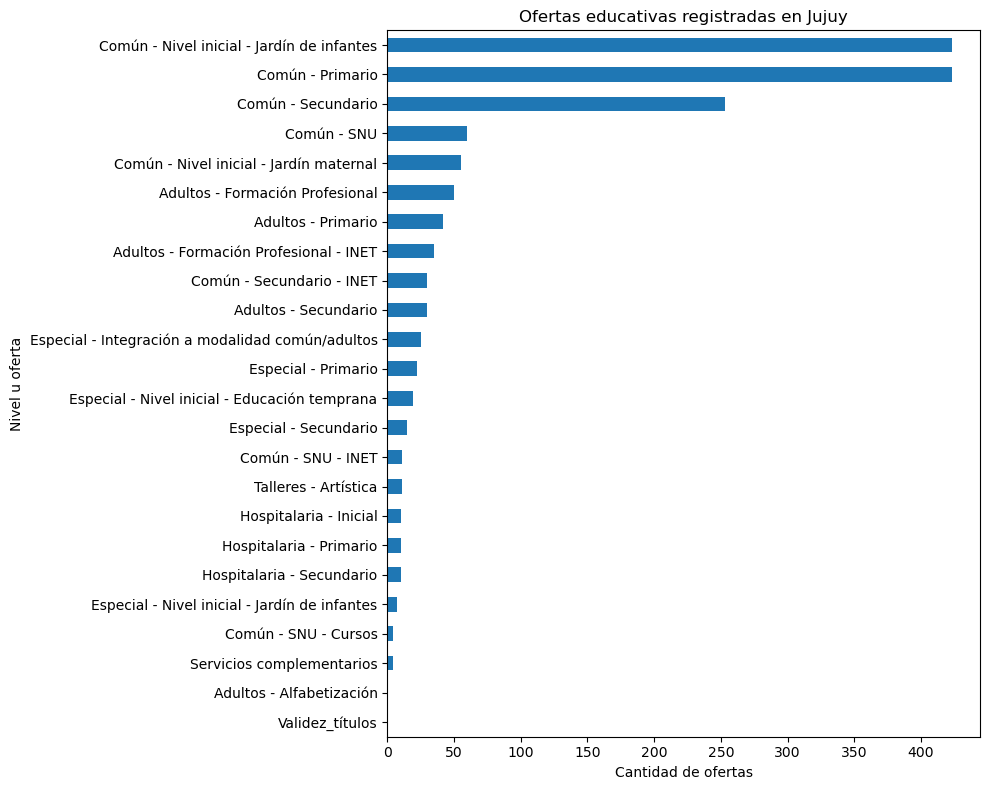

In [31]:
niveles.sort_values().plot(
    kind="barh",
    figsize=(10, 8)
)

plt.title("Ofertas educativas registradas en Jujuy")
plt.xlabel("Cantidad de ofertas")
plt.ylabel("Nivel u oferta")
plt.tight_layout()
plt.show()

### Oferta secundaria y superior

Para el proyecto nos interesa conocer dónde hay establecimientos con oferta secundaria y dónde existe oferta superior no universitaria (SNU).

Vamos a considerar todas las variantes de secundaria y SNU que aparecen en el padrón.

In [32]:
columnas_secundaria = [
    "Común - Secundario",
    "Común - Secundario - INET",
    "Especial - Secundario",
    "Adultos - Secundario",
    "Hospitalaria - Secundario"
]

columnas_snu = [
    "Común - SNU",
    "Común - SNU - INET",
    "Común - SNU - Cursos"
]

mask_sec = jj[columnas_secundaria].sum(axis=1) > 0
mask_snu = jj[columnas_snu].sum(axis=1) > 0

print("Establecimientos con secundaria:", int(mask_sec.sum()))
print("Establecimientos con SNU:", int(mask_snu.sum()))
print("Establecimientos con secundaria o SNU:", int((mask_sec | mask_snu).sum()))

Establecimientos con secundaria: 293
Establecimientos con SNU: 60
Establecimientos con secundaria o SNU: 353


In [33]:
# Agrupamos por codigo de localidad para no contar dos veces nombres repetidos
total_ubicaciones = jj["Código de localidad"].nunique()
ubicaciones_con_oferta = jj.loc[mask_sec | mask_snu, "Código de localidad"].nunique()

print("Ubicaciones territoriales:", total_ubicaciones)
print("Con secundaria o SNU:", ubicaciones_con_oferta)
print("Sin secundaria ni SNU:", total_ubicaciones - ubicaciones_con_oferta)

Ubicaciones territoriales: 257
Con secundaria o SNU: 130
Sin secundaria ni SNU: 127


In [34]:
cobertura_localidades = pd.DataFrame({
    "indicador": [
        "Ubicaciones con secundaria",
        "Ubicaciones con SNU",
        "Ubicaciones con secundaria o SNU",
        "Ubicaciones sin secundaria ni SNU"
    ],
    "cantidad": [
        jj.loc[mask_sec, "Código de localidad"].nunique(),
        jj.loc[mask_snu, "Código de localidad"].nunique(),
        ubicaciones_con_oferta,
        total_ubicaciones - ubicaciones_con_oferta
    ]
})

cobertura_localidades

,indicador,cantidad
0,Ubicaciones con secundaria,130
1,Ubicaciones con SNU,17
2,Ubicaciones con secundaria o SNU,130
3,Ubicaciones sin secundaria ni SNU,127


### Comparacion por departamento

Ahora comparamos la cantidad de establecimientos con secundaria y SNU en cada departamento.

In [35]:
cobertura_departamento = pd.DataFrame({
    "Secundaria": jj.loc[mask_sec].groupby("Departamento")["Cueanexo"].count(),
    "SNU": jj.loc[mask_snu].groupby("Departamento")["Cueanexo"].count()
}).fillna(0).astype(int)

cobertura_departamento

,Secundaria,SNU
Departamento,,
COCHINOCA,13,1
DOCTOR MANUEL BELGRANO,86,33
EL CARMEN,34,5
HUMAHUACA,22,2
LEDESMA,21,7
PALPALA,15,2
RINCONADA,7,0
SAN ANTONIO,3,0
SAN PEDRO,30,5


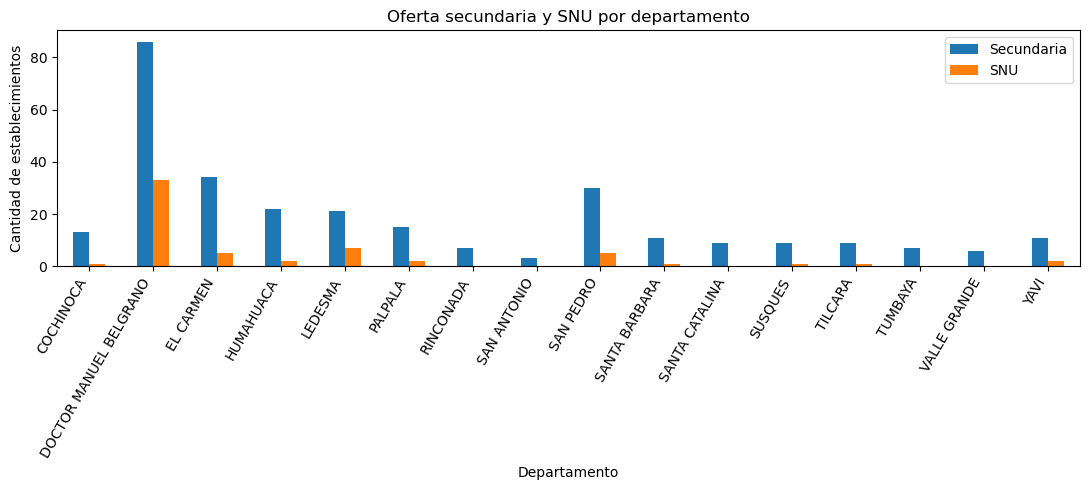

In [36]:
cobertura_departamento.plot(
    kind="bar",
    figsize=(11, 5)
)

plt.title("Oferta secundaria y SNU por departamento")
plt.xlabel("Departamento")
plt.ylabel("Cantidad de establecimientos")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

## <U>Etapa 10</U>: Validacion de los datos de Jujuy

Vamos a revisar los datos faltantes y algunos campos que pueden presentar problemas. No vamos a eliminar registros por estas observaciones sin investigar primero su origen.

In [37]:
print("Valores nulos en Jujuy")
nulos_jujuy = jj.isnull().sum()
nulos_jujuy[nulos_jujuy > 0]

Valores nulos en Jujuy


C.P.                                 4
Mail                               283
Total de hogares                     1
Hogares con población de 3 a 17      1
Población de 3 a 17                  1
dtype: int64

In [38]:
print("Registros duplicados exactos:", jj.duplicated().sum())
print("Codigos Cueanexo unicos:", jj["Cueanexo"].is_unique)
print("Codigos de localidad unicos:", jj["Código de localidad"].nunique())

Registros duplicados exactos: 0
Codigos Cueanexo unicos: True
Codigos de localidad unicos: 257


### Revision de espacios en los textos

Revisamos si algunos nombres tienen espacios al comienzo, al final o espacios dobles. Por ahora solo los identificamos; no modificamos los nombres originales.

In [39]:
revision_textos = []

for col in ["Departamento", "Localidad", "Nombre"]:
    texto = jj[col].fillna("").astype(str)
    revision_textos.append({
        "columna": col,
        "espacios_alrededor": int((texto != texto.str.strip()).sum()),
        "espacios_dobles": int(texto.str.contains("  ", regex=False).sum())
    })

pd.DataFrame(revision_textos)

,columna,espacios_alrededor,espacios_dobles
0,Departamento,0,0
1,Localidad,0,0
2,Nombre,71,30


### Revision de los codigos

Comprobamos la longitud de los códigos utilizados para identificar departamentos, localidades y establecimientos.

In [40]:
for col in ["Código de departamento", "Código de localidad", "Cueanexo"]:
    print(col, ":", sorted(jj[col].astype(str).str.len().unique()))

Código de departamento : [np.int64(5)]
Código de localidad : [np.int64(8)]
Cueanexo : [np.int64(9)]


### Revision de los indicadores de hogares y población

Estas tres columnas tienen nombres que podrían interpretarse como cantidades. Sin embargo, sus valores son decimales y se encuentran entre 0 y 1 aproximadamente. Por ese motivo no las vamos a utilizar como cantidades de hogares o personas.

In [41]:
columnas_indicadores = [
    "Total de hogares",
    "Hogares con población de 3 a 17",
    "Población de 3 a 17"
]

jj[columnas_indicadores].describe()

,Total de hogares,Hogares con población de 3 a 17,Población de 3 a 17
count,1086.000000,1086.000000,1086.000000
unique,114.000000,115.000000,115.000000
top,0.136233,0.138971,0.154751
freq,66.000000,66.000000,66.000000


## <U>Etapa 11</U>: Preparacion y exportacion de los datos

Para el proyecto vamos a guardar una versión de Jujuy con las columnas necesarias para el análisis. Se excluyen datos de contacto y domicilio porque no son necesarios para estudiar la distribución territorial de la oferta educativa.

También vamos a crear un segundo archivo agrupado por departamento y localidad.

In [42]:
columnas_base = [
    "Jurisdicción", "Sector", "Ámbito", "Departamento",
    "Código de departamento", "Localidad", "Código de localidad", "Cueanexo"
]

columnas_procesadas = columnas_base + columnas_oferta

padron_jujuy = jj[columnas_procesadas].copy()

print("Tamaño del archivo procesado:", padron_jujuy.shape)
padron_jujuy.head()

Tamaño del archivo procesado: (1087, 35)


,Jurisdicción,Sector,Ámbito,Departamento,Código de departamento,Localidad,Código de localidad,Cueanexo,Modalidad - Común,Modalidad - Especial,...,Adultos - Secundario,Adultos - Formación Profesional,Adultos - Formación Profesional - INET,Adultos - Alfabetización,Hospitalaria - Inicial,Hospitalaria - Primario,Hospitalaria - Secundario,Talleres - Artística,Servicios complementarios,Validez_títulos
39974,Jujuy,Estatal,Urbano,DOCTOR MANUEL BELGRANO,38021,SAN SALVADOR DE JUJUY,38021080,380000100,0,0,...,0,0,0,0,0,0,0,0,0,0
39975,Jujuy,Estatal,Urbano,DOCTOR MANUEL BELGRANO,38021,SAN SALVADOR DE JUJUY,38021080,380000200,1,0,...,0,0,0,0,0,0,0,0,0,0
39976,Jujuy,Estatal,Urbano,DOCTOR MANUEL BELGRANO,38021,SAN SALVADOR DE JUJUY,38021080,380000300,1,0,...,0,0,0,0,0,0,0,0,0,0
39977,Jujuy,Estatal,Urbano,DOCTOR MANUEL BELGRANO,38021,SAN SALVADOR DE JUJUY,38021080,380000400,1,0,...,0,0,0,0,0,0,0,0,0,0
39978,Jujuy,Privado,Urbano,DOCTOR MANUEL BELGRANO,38021,SAN SALVADOR DE JUJUY,38021080,380000600,1,0,...,0,0,0,0,0,0,0,0,0,0


In [43]:
# Resumen por ubicacion territorial
padron_localidades = (
    jj.groupby(["Código de localidad", "Departamento", "Localidad"])
      .agg(
          establecimientos=("Cueanexo", "count"),
          estatales=("Sector", lambda x: (x == "Estatal").sum()),
          privados=("Sector", lambda x: (x == "Privado").sum()),
          sociales_cooperativos=("Sector", lambda x: (x == "Social/cooperativa").sum()),
          urbanos=("Ámbito", lambda x: (x == "Urbano").sum()),
          rurales=("Ámbito", lambda x: (x == "Rural").sum()),
          con_secundaria=("Cueanexo", lambda x: int(mask_sec.loc[x.index].sum())),
          con_snu=("Cueanexo", lambda x: int(mask_snu.loc[x.index].sum()))
      )
      .reset_index()
)

print("Ubicaciones en el resumen:", len(padron_localidades))
padron_localidades.head()

Ubicaciones en el resumen: 257


,Código de localidad,Departamento,Localidad,establecimientos,estatales,privados,sociales_cooperativos,urbanos,rurales,con_secundaria,con_snu
0,38007001,COCHINOCA,ABDON CASTRO TOLAY,2,2,0,0,0,2,1,0
1,38007002,COCHINOCA,ABRA PAMPA,18,18,0,0,17,1,4,1
2,38007003,COCHINOCA,ABRALAITE,1,1,0,0,0,1,0,0
3,38007009,COCHINOCA,AGUA DE CASTILLA,2,2,0,0,0,2,1,0
4,38007028,COCHINOCA,CASABINDO,2,2,0,0,0,2,1,0


In [44]:
archivo_padron = PROCESADOS / "padron_jujuy_preliminar.csv"
archivo_localidades = PROCESADOS / "padron_jujuy_por_localidad.csv"

padron_jujuy.to_csv(archivo_padron, index=False, encoding="utf-8-sig")
padron_localidades.to_csv(archivo_localidades, index=False, encoding="utf-8-sig")

print("Archivos exportados correctamente")
print(archivo_padron)
print(archivo_localidades)

Archivos exportados correctamente
Datos/Procesados/padron_jujuy_preliminar.csv
Datos/Procesados/padron_jujuy_por_localidad.csv


In [45]:
# Comprobamos que los archivos se hayan guardado correctamente
verificacion_padron = pd.read_csv(archivo_padron)
verificacion_localidades = pd.read_csv(archivo_localidades)

print("Padron:", verificacion_padron.shape)
print("Localidades:", verificacion_localidades.shape)
print("¿Se conserva la cantidad de registros?:", len(verificacion_padron) == len(jj))
print("¿Se conserva la cantidad de ubicaciones?:", len(verificacion_localidades) == jj["Código de localidad"].nunique())

Padron: (1087, 35)
Localidades: (257, 11)
¿Se conserva la cantidad de registros?: True
¿Se conserva la cantidad de ubicaciones?: True


## <U>Etapa 12</U>: Resumen del analisis

Con este análisis pudimos separar los establecimientos de Jujuy, conocer su distribución territorial y revisar la oferta secundaria y superior.

El padrón se utilizará como información de contexto territorial. No contiene calificaciones ni intereses individuales, por lo que no se utilizará para construir perfiles de estudiantes.

In [46]:
print("RESUMEN DEL PADRON DE JUJUY")
print("----------------------------")
print("Establecimientos:", len(jj))
print("Departamentos:", jj["Departamento"].nunique())
print("Localidades por nombre:", jj["Localidad"].nunique())
print("Ubicaciones territoriales:", jj["Código de localidad"].nunique())
print("Con oferta secundaria:", int(mask_sec.sum()))
print("Con oferta SNU:", int(mask_snu.sum()))
print("Ubicaciones con secundaria o SNU:", ubicaciones_con_oferta)
print("Ubicaciones sin secundaria ni SNU:", total_ubicaciones - ubicaciones_con_oferta)

RESUMEN DEL PADRON DE JUJUY
----------------------------
Establecimientos: 1087
Departamentos: 16
Localidades por nombre: 249
Ubicaciones territoriales: 257
Con oferta secundaria: 293
Con oferta SNU: 60
Ubicaciones con secundaria o SNU: 130
Ubicaciones sin secundaria ni SNU: 127
